# 04 · Comparing the three counting methods
**Goal:** do kallisto, STAR and RSEM give the same biological answers? **Input:** Euler results (notebook 01). **Output:** `results/compare/`. **Kernel:** R (`ir`) · **Time:** ~5 min.

| Method | Reads go to | Counts |
|---|---|---|
| **kallisto** | transcripts (pseudoalignment); EM shares reads between isoforms | estimated |
| **STAR** (`GeneCounts`) | the genome; only uniquely mapped reads counted per gene | whole numbers |
| **RSEM** | STAR's alignments to transcripts (a counting step after STAR); EM shares multi-mapping reads | expected |

All three use the same trimmed reads, the same M39 annotation and the same DESeq2 code (outlier SRR21355389 excluded from aging, as in notebook 03). STAR vs RSEM therefore differ in counting only; kallisto also in mapping. Measures: **Spearman correlation** (agreement of rankings), **Jaccard index** (shared ÷ combined DEGs), **same direction** (share of shared DEGs with the same log2FC sign). See [docs/glossary.md](../docs/glossary.md).

In [1]:
# txi: kallisto counts; rsem: RSEM counts (both tximport lists); star: STAR counts (genes x runs); all use GENCODE M39 gene ids
source('../R/helpers.R')
samples <- load_samples()
x <- load_txi(rownames(samples)); txi <- x$txi; genes <- x$genes
rsem <- load_rsem(rownames(samples))
star <- load_star_counts()[, rownames(samples)]
ids <- Reduce(intersect, list(rownames(txi$counts), rownames(rsem$counts), rownames(star)))
cat('genes: kallisto', nrow(txi$counts), '| RSEM', nrow(rsem$counts), '| STAR', nrow(star), '| shared by all three', length(ids), '\n')

genes: kallisto 78348 | RSEM 78289 | STAR 78289 | shared by all three 78289 


## 1 · Counts per sample
Per sample: Spearman correlation of gene counts between each pair of methods, and total counts in millions (STAR counts only uniquely mapped reads, so its totals are lower).

In [2]:
# one row per sample: correlation per pair of methods and total counts (millions) per method, over genes present in all three
m <- list(kallisto = txi$counts[ids, ], STAR = star[ids, ], RSEM = rsem$counts[ids, ])
rho <- \(a, b) map_dbl(rownames(samples), \(s) cor(m[[a]][, s], m[[b]][, s], method = 'spearman'))
per_sample <- tibble(srr = rownames(samples), group = samples$group,
  spearman_kallisto_STAR = rho('kallisto', 'STAR'), spearman_kallisto_RSEM = rho('kallisto', 'RSEM'), spearman_STAR_RSEM = rho('STAR', 'RSEM'),
  kallisto_M = colSums(m$kallisto) / 1e6, STAR_M = colSums(m$STAR) / 1e6, RSEM_M = colSums(m$RSEM) / 1e6)
per_sample

srr,group,spearman_kallisto_STAR,spearman_kallisto_RSEM,spearman_STAR_RSEM,kallisto_M,STAR_M,RSEM_M
<chr>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
SRR21355401,aging 3mo,0.8511144,0.8453871,0.8836863,9.784402,7.288824,7.383320
SRR21355396,aging 3mo,0.8496183,0.8502663,0.8937497,17.368512,12.818784,12.908025
SRR21355392,aging 3mo,0.8551451,0.8492700,0.8879860,10.866549,8.066851,8.188908
SRR21355388,aging 3mo,0.8496001,0.8469507,0.8929501,11.433896,8.406642,8.492186
SRR21355398,aging 18mo,0.8606684,0.8603267,0.9020248,4.350757,3.188999,3.243133
SRR21355394,aging 18mo,0.8558280,0.8492704,0.8940471,5.313600,4.011262,3.983007
SRR21355390,aging 18mo,0.8500679,0.8501149,0.8967946,18.348354,13.253364,13.305523
SRR21355386,aging 18mo,0.8535198,0.8488484,0.8952995,6.349880,4.794236,4.789273
SRR21355397,aging 21mo,0.8517557,0.8511993,0.8972525,9.496894,7.151945,7.293882


## 2 · Differential expression with each method

In [3]:
# the four DESeq2 analyses of notebook 03 for each method (dds = fitted models, de = result tables); counts of up / down DEGs
counts <- list(kallisto = txi, STAR = star, RSEM = rsem)
dds <- lapply(counts, run_dds, samples = samples)
de <- lapply(dds, de_tables, genes = genes)
bind_rows(lapply(de, \(r) bind_rows(lapply(r, n_deg), .id = 'contrast')), .id = 'method')

method,contrast,up,down
<chr>,<chr>,<int>,<int>
kallisto,aging_18v3,101,25
kallisto,aging_21v3,82,52
kallisto,aDR,64,75
kallisto,YMP,17,24
STAR,aging_18v3,117,32
STAR,aging_21v3,98,70
STAR,aDR,70,115
STAR,YMP,9,17
RSEM,aging_18v3,95,20


### Agreement per contrast
`total_DEG_a` / `_b` = all DEGs of each method; the other columns use only genes with a valid p-value in **both** (`genes_tested_both`), so `DEG_a` / `DEG_b` can be smaller. `lfc_spearman_all` / `_sig` = log2FC rank correlation over all tested genes / genes significant in either method.

In [4]:
# agreement table: every pair of methods, every comparison
pairs <- list(c('kallisto', 'STAR'), c('kallisto', 'RSEM'), c('STAR', 'RSEM'))
cmp <- bind_rows(lapply(pairs, \(p) bind_rows(lapply(names(de$kallisto), \(n)
  compare_contrast(de[[p[1]]][[n]], de[[p[2]]][[n]]) %>% mutate(contrast = n))) %>% mutate(method_a = p[1], method_b = p[2]))) %>%
  relocate(method_a, method_b, contrast)
cmp

method_a,method_b,contrast,total_DEG_a,total_DEG_b,genes_tested_both,DEG_a,DEG_b,shared,jaccard,same_direction,lfc_spearman_all,lfc_spearman_sig
<chr>,<chr>,<chr>,<int>,<int>,<int>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
kallisto,STAR,aging_18v3,126,149,16543,111,145,89,0.53,1,0.781,0.922
kallisto,STAR,aging_21v3,134,168,17104,121,168,98,0.51,1,0.779,0.962
kallisto,STAR,aDR,139,185,13831,130,185,80,0.34,1,0.828,0.948
kallisto,STAR,YMP,41,26,16149,32,26,19,0.49,1,0.824,0.880
kallisto,RSEM,aging_18v3,126,115,15812,121,115,86,0.57,1,0.839,0.903
kallisto,RSEM,aging_21v3,134,116,16725,128,116,89,0.57,1,0.824,0.964
kallisto,RSEM,aDR,139,118,12913,128,117,84,0.52,1,0.887,0.954
kallisto,RSEM,YMP,41,50,17097,40,48,25,0.40,1,0.851,0.916
STAR,RSEM,aging_18v3,149,115,15347,140,105,79,0.48,1,0.762,0.948


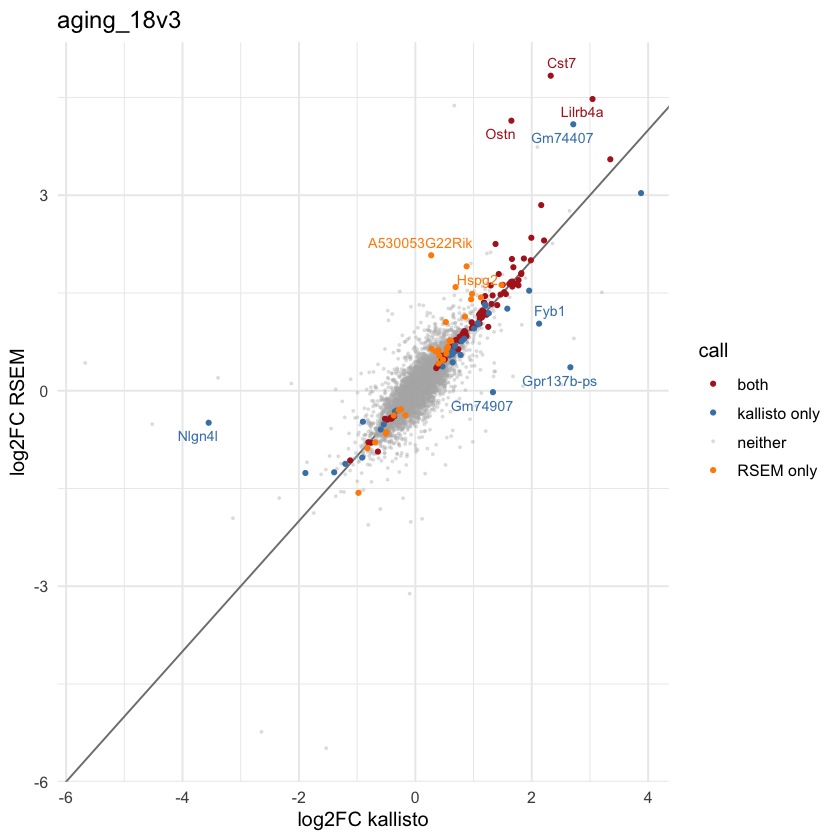

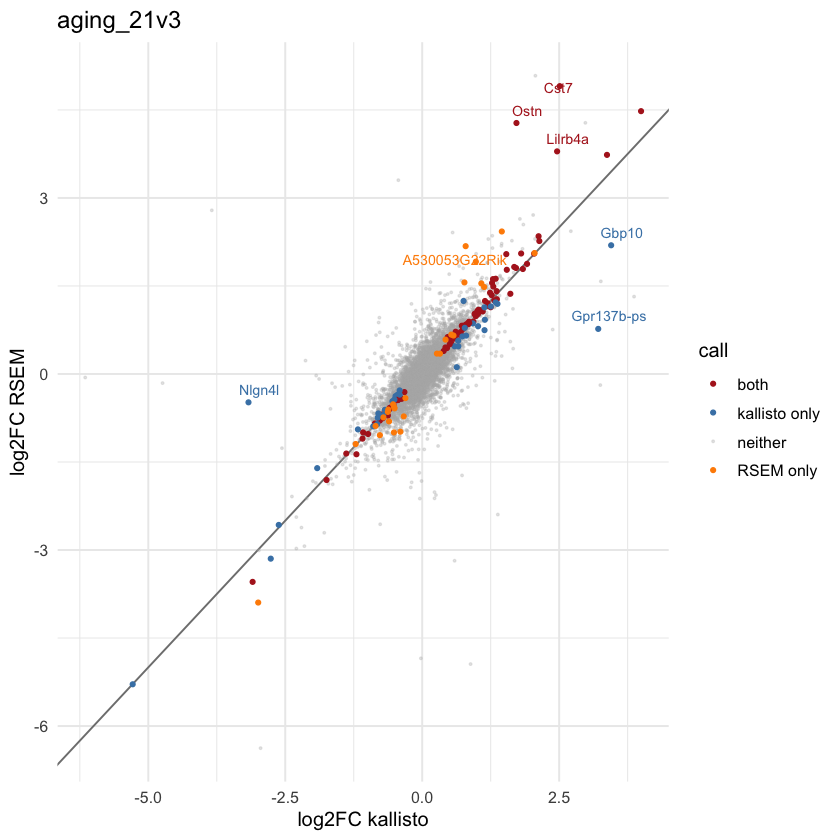

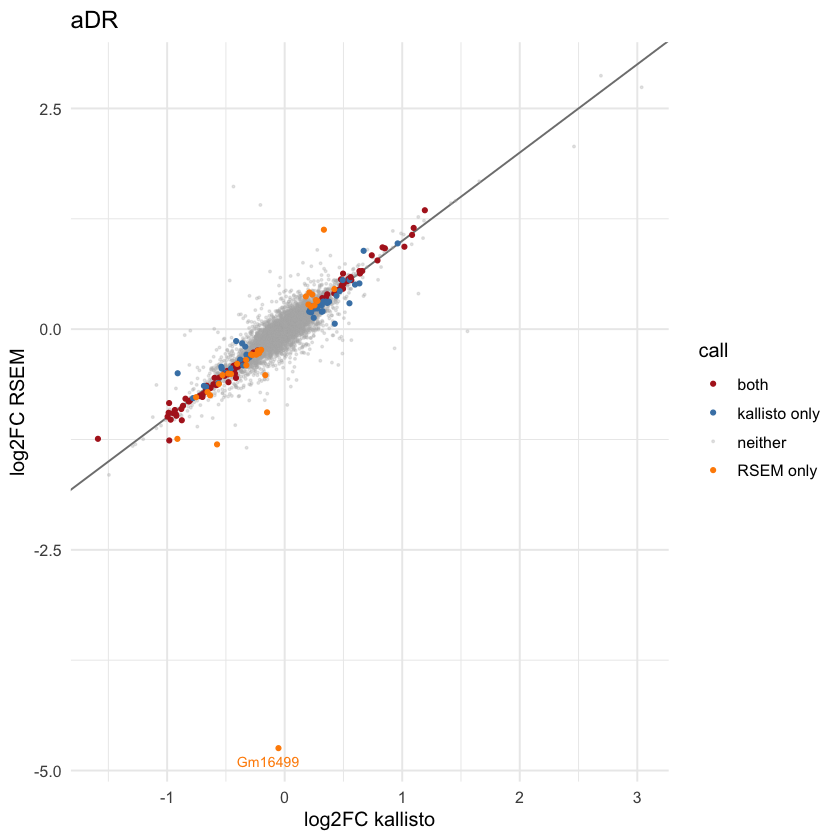

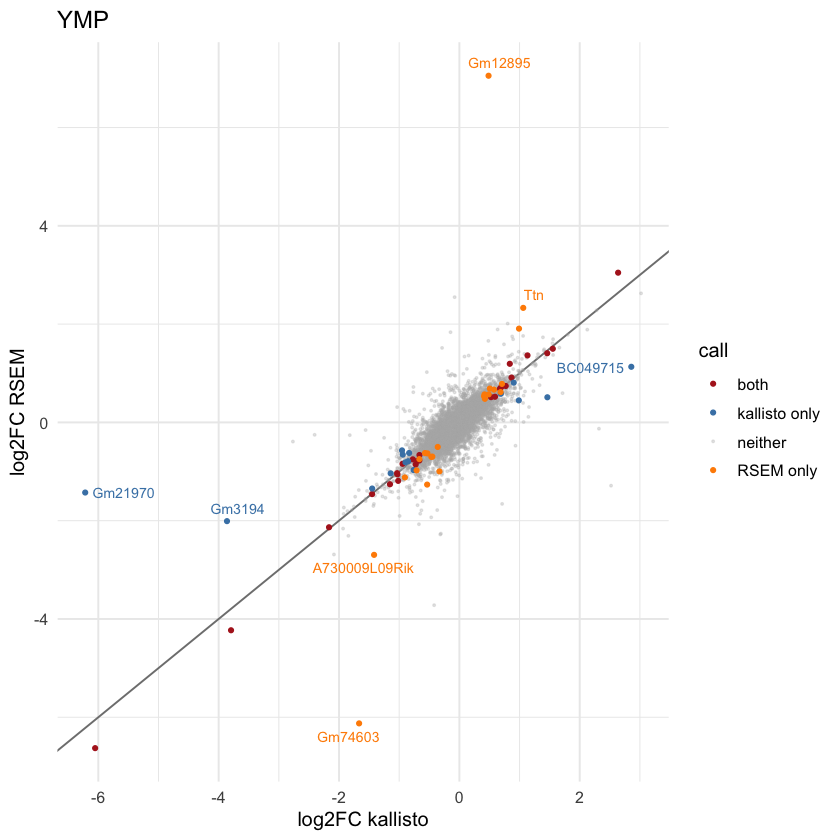

In [5]:
# log2FC of one method (x) against another (y) per gene; colour = which method calls the gene a DEG. Change PLOT_PAIR to see another pair.
PLOT_PAIR <- c('kallisto', 'RSEM')
for (n in names(de$kallisto)) print(lfc_scatter(de[[PLOT_PAIR[1]]][[n]], de[[PLOT_PAIR[2]]][[n]], n, names = PLOT_PAIR))

## 3 · Genes called by only one method
Are the disagreements mostly lowly expressed genes? (`median_baseMean` = median average normalised count.)

In [6]:
# per pair and comparison: genes called by both / only by the first / only by the second method, with typical expression
only <- function(a, b, alpha = 0.05) inner_join(a, b, by = 'gene_id', suffix = c('_a', '_b')) %>% filter(!is.na(padj_a), !is.na(padj_b)) %>%
  mutate(call = case_when(padj_a < alpha & padj_b < alpha ~ 'both', padj_a < alpha ~ 'first only', padj_b < alpha ~ 'second only', TRUE ~ 'neither'))
bind_rows(lapply(pairs, \(p) bind_rows(lapply(names(de$kallisto), \(cn) only(de[[p[1]]][[cn]], de[[p[2]]][[cn]]) %>% filter(call != 'neither') %>%
  group_by(call) %>% summarise(n_genes = n(), median_baseMean = round(median((baseMean_a + baseMean_b) / 2)), .groups = 'drop') %>% mutate(contrast = cn))) %>%
  mutate(first = p[1], second = p[2]))) %>% relocate(first, second, contrast)

first,second,contrast,call,n_genes,median_baseMean
<chr>,<chr>,<chr>,<chr>,<int>,<dbl>
kallisto,STAR,aging_18v3,both,89,95
kallisto,STAR,aging_18v3,first only,22,138
kallisto,STAR,aging_18v3,second only,56,123
kallisto,STAR,aging_21v3,both,98,178
kallisto,STAR,aging_21v3,first only,23,145
kallisto,STAR,aging_21v3,second only,70,99
kallisto,STAR,aDR,both,80,507
kallisto,STAR,aDR,first only,50,447
kallisto,STAR,aDR,second only,105,334


## 4 · Genes highlighted in the paper
Aging genes (C4b, Trem2, …) and circadian genes induced by dietary restriction (Cry1, Usp2, Ciart, …) with each method.

In [7]:
# log2FC and padj of the paper's genes, the three methods side by side
key <- list(aging_21v3 = c('C4b', 'Trem2', 'Gpr17', 'Gfap', 'Ctss', 'Tyrobp'), aDR = c('Cry1', 'Usp2', 'Ciart', 'Cirbp', 'Dbp'))
bind_rows(lapply(names(key), \(n) {
  f <- \(m) de[[m]][[n]] %>% filter(symbol %in% key[[n]]) %>% transmute(contrast = n, symbol, !!paste0('lfc_', m) := round(log2FoldChange, 2), !!paste0('padj_', m) := signif(padj, 2))
  purrr::reduce(lapply(names(de), f), inner_join, by = c('contrast', 'symbol'))
}))

contrast,symbol,lfc_kallisto,padj_kallisto,lfc_STAR,padj_STAR,lfc_RSEM,padj_RSEM
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
aging_21v3,C4b,1.91,9.0e-15,2.07,6.9e-25,1.88,2.2e-12
aging_21v3,Gfap,0.85,1.1e-09,0.85,6.1e-12,0.85,1.0e-10
aging_21v3,Ctss,0.98,4.8e-08,0.98,3.4e-09,1.00,1.8e-07
aging_21v3,Tyrobp,1.25,4.2e-06,1.21,5.7e-07,1.14,1.8e-04
aging_21v3,Trem2,1.36,1.7e-04,1.37,1.5e-05,1.41,1.5e-03
aging_21v3,Gpr17,-1.39,6.4e-04,-1.34,9.6e-05,-1.36,3.8e-03
aDR,Ciart,0.79,2.6e-09,0.85,7.3e-14,0.78,6.8e-07
aDR,Dbp,0.42,1.6e-04,0.44,8.8e-05,0.40,5.3e-04
aDR,Cirbp,0.57,4.9e-04,0.59,3.9e-05,0.56,1.8e-03


## 5 · Evidence for choosing a method
No method is assumed best. The measurements below were fixed in advance ([docs/pipeline.md](../docs/pipeline.md#choosing-the-counting-method)); none uses the biological conclusion. A method is a poor choice only if clearly worse on several. The positive controls are a sanity check, not a selector (that would be circular).

### 5a · Usable data and replicate agreement

In [8]:
# usable data: share of the trimmed read pairs that end up counted in a gene; genes detected (>= 10 counts in >= 3 runs)
inp <- read_csv(file.path(ROOT, 'results/star/star_qc.csv'), show_col_types = FALSE) %>% column_to_rownames('SRR')
pairs_in <- inp[rownames(samples), 'input_pairs_M'] * 1e6          # pairs that entered kallisto and STAR
cnt <- lapply(counts, \(m) if (is.matrix(m)) m[, rownames(samples)] else m$counts[, rownames(samples)])
usable <- bind_rows(lapply(names(cnt), \(m) tibble(method = m, counted_pairs_pct = 100 * colSums(cnt[[m]]) / pairs_in)))
use_tab <- usable %>% group_by(method) %>% summarise(counted_pairs_pct_median = round(median(counted_pairs_pct), 1), min = round(min(counted_pairs_pct), 1), max = round(max(counted_pairs_pct), 1)) %>%
  left_join(tibble(method = names(cnt), genes_detected = map_int(cnt, \(m) sum(rowSums(m >= 10) >= 3))), by = 'method')
use_tab

method,counted_pairs_pct_median,min,max,genes_detected
<chr>,<dbl>,<dbl>,<dbl>,<int>
RSEM,54.8,47.2,60.1,19311
STAR,54.3,47.0,58.7,20649
kallisto,68.8,65.1,72.5,26273


In [9]:
# replicate agreement: median pairwise Pearson r of log2 CPM between the mice of a group (genes present and expressed in all three methods)
keep <- ids[Reduce(`&`, lapply(cnt, \(m) rowMeans(m[ids, ]) >= 10))]
lcpm <- lapply(cnt, \(m) { m <- m[keep, ]; log2(sweep(m, 2, colSums(m) / 1e6, '/') + 1) })
rep_tab <- bind_rows(lapply(names(lcpm), \(mth) bind_rows(lapply(split(rownames(samples), samples$group), \(s) {
  cm <- cor(lcpm[[mth]][, s]); tibble(n_mice = length(s), median_pairwise_r = median(cm[lower.tri(cm)])) }), .id = 'group') %>% mutate(method = mth))) %>% relocate(method)
rep_tab %>% mutate(median_pairwise_r = round(median_pairwise_r, 4)) %>% pivot_wider(names_from = method, values_from = median_pairwise_r)

group,n_mice,kallisto,STAR,RSEM
<chr>,<int>,<dbl>,<dbl>,<dbl>
aging 3mo,4,0.9903,0.9896,0.9891
aging 18mo,4,0.9848,0.9834,0.9826
aging 21mo,4,0.9801,0.9793,0.9789
AL,4,0.9884,0.9880,0.9878
aDR,5,0.9875,0.9874,0.9873
PBS,3,0.9855,0.9855,0.9850
YMP,3,0.9920,0.9916,0.9914


### 5b · Noise and stability
`dispersion` = median DESeq2 dispersion over genes tested by all methods (lower = more power; count scales differ, so compare with care). `DEG_without` / `DEG_with` = aging DEGs (21 vs 3 months) without / with the outlier SRR21355389; `jaccard_outlier` = their overlap (1 = independent of that mouse).

In [10]:
# dispersion per model and stability of the aging DEGs to the outlier
tested <- Reduce(intersect, lapply(dds, \(d) Reduce(intersect, lapply(d, rownames))))
disp <- bind_rows(lapply(names(dds), \(m) tibble(method = m, !!!lapply(dds[[m]], \(d) round(median(setNames(dispersions(d), rownames(d))[intersect(rownames(d), tested)], na.rm = TRUE), 3)))))
s_all <- samples %>% filter(cohort == 'aging') %>% mutate(group = droplevels(group))
stab <- bind_rows(lapply(names(counts), \(m) {
  all12 <- de_table(make_dds(counts[[m]], s_all, ~ sex + group, min_n = 4), c('group', 'aging 21mo', 'aging 3mo'), genes)
  cd <- compare_de(de[[m]]$aging_21v3, all12)
  tibble(method = m, DEG_without = cd$DEG_a, DEG_with = cd$DEG_b, jaccard_outlier = round(cd$DEG_both / (cd$DEG_a + cd$DEG_b - cd$DEG_both), 2)) }))
left_join(rename_with(disp, ~ paste0('dispersion_', .x), -method), stab, by = 'method')

method,dispersion_aging,dispersion_aDR,dispersion_YMP,DEG_without,DEG_with,jaccard_outlier
<chr>,<dbl>,<dbl>,<dbl>,<int>,<int>,<dbl>
kallisto,0.019,0.014,0.017,132,279,0.42
STAR,0.013,0.011,0.015,168,307,0.48
RSEM,0.022,0.017,0.019,114,239,0.43


### 5c · Positive controls and agreement with the other methods

In [11]:
# positive controls: genes the paper reports as up with aging (5 inflammation genes) and as up with aDR (23 circadian/cycling genes); mean Jaccard with the other two methods
up_aging <- c('C4b', 'Trem2', 'Ctss', 'Tyrobp', 'Gfap')
adr23 <- c('Chordc1','Cxcl12','Fabp7','Kdr','Adipor2','Gjb6','Mertk','Cry1','Klf15','Dbp','Usp2','Etnppl','Ciart','Sult1a1','Zbtb16','Fkbp5','Sgk1','Tsc22d3','Cirbp','Rbm3','Plin4','Fmo2','Hif3a')
ctrl <- bind_rows(lapply(names(de), \(m) tibble(method = m,
  aging_genes_up_of_5 = sum(filter(de[[m]]$aging_21v3, symbol %in% up_aging)$log2FoldChange > 0),
  aDR_genes_up_of_23 = sum(filter(de[[m]]$aDR, symbol %in% adr23)$log2FoldChange > 0),
  mean_jaccard_with_others = round(mean(filter(cmp, method_a == m | method_b == m)$jaccard), 2))))
ctrl

method,aging_genes_up_of_5,aDR_genes_up_of_23,mean_jaccard_with_others
<chr>,<int>,<int>,<dbl>
kallisto,5,19,0.49
STAR,5,19,0.45
RSEM,5,19,0.47


### 5d · The evidence table
One row per method, saved to `results/compare/method_evidence.csv`. Practical criteria (run time, memory) are in [docs/pipeline.md](../docs/pipeline.md).

In [12]:
# all measurements together, one row per method
evidence <- use_tab %>% left_join(rep_tab %>% group_by(method) %>% summarise(replicate_r_median = round(median(median_pairwise_r), 4)), by = 'method') %>%
  left_join(rename_with(disp, ~ paste0('dispersion_', .x), -method), by = 'method') %>% left_join(stab, by = 'method') %>% left_join(ctrl, by = 'method')
evidence

method,counted_pairs_pct_median,min,max,genes_detected,replicate_r_median,dispersion_aging,dispersion_aDR,dispersion_YMP,DEG_without,DEG_with,jaccard_outlier,aging_genes_up_of_5,aDR_genes_up_of_23,mean_jaccard_with_others
<chr>,<dbl>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<dbl>,<int>,<int>,<dbl>
RSEM,54.8,47.2,60.1,19311,0.9873,0.022,0.017,0.019,114,239,0.43,5,19,0.47
STAR,54.3,47.0,58.7,20649,0.9874,0.013,0.011,0.015,168,307,0.48,5,19,0.45
kallisto,68.8,65.1,72.5,26273,0.9875,0.019,0.014,0.017,132,279,0.42,5,19,0.49


## 6 · Save

In [13]:
# agreement tables for the report (per-gene tables of STAR and RSEM stay out of git)
dir.create(file.path(ROOT, 'results/compare'), showWarnings = FALSE)
write_csv(cmp, file.path(ROOT, 'results/compare/de_agreement.csv'))
write_csv(per_sample, file.path(ROOT, 'results/compare/counts_per_sample.csv'))
write_csv(evidence, file.path(ROOT, 'results/compare/method_evidence.csv'))
for (m in c('STAR', 'RSEM')) imap(de[[m]], \(r, n) write_csv(r, file.path(ROOT, 'results/compare', paste0(tolower(m), '_', n, '.csv')))) %>% invisible()
list.files(file.path(ROOT, 'results/compare'))

[1] "counts_per_sample.csv" "de_agreement.csv"      "method_evidence.csv"  
 [4] "rsem_aDR.csv"          "rsem_aging_18v3.csv"   "rsem_aging_21v3.csv"  
 [7] "rsem_YMP.csv"          "star_aDR.csv"          "star_aging_18v3.csv"  
[10] "star_aging_21v3.csv"   "star_YMP.csv"